## 2. Embedding model

An embedding model converts text into a dense numerical vector. Unlike a generative model, it does not product text token-by-token. 

High level mental model:

text <br>
--> tokenizer <br>
--> encoder <br>
--> vector representation

Example model we will use: Qwen/Qwen3-Embedding-0.6B (small model, supports upto 32K context and produces embeddings upto 1024 dimensions).

A typical output is a 384-dimensional vector.

Embeddings are used for multiple purposes:
* Similarity matching
* Linear heads


In [1]:
## Prerequisites
%pip install sentence-transformers huggingface_hub

Note: you may need to restart the kernel to use updated packages.


In [2]:
print("Starting setup; importing Hugging Face libraries...", flush=True)
from huggingface_hub import snapshot_download
from huggingface_hub.utils import enable_progress_bars
from sentence_transformers import SentenceTransformer

enable_progress_bars()

EMBEDDING_MODEL_ID = "Qwen/Qwen3-Embedding-0.6B"

## Download; separating this out to be able to see the progress.
print(f"Downloading model files for {EMBEDDING_MODEL_ID} (if not already cached)...")
model_path = snapshot_download(repo_id=EMBEDDING_MODEL_ID)
print("Download complete.")

## Load the model.
embedding_model = SentenceTransformer(model_path)
print("Embedding model loaded.")

texts = [
    "EGFR T790M is a resistance mutation.",
    "The patient developed resistance to the therapy due to the EGFR T790M mutation.",
]

## Generate embeddings. 
embeddings = embedding_model.encode(texts)
print("Embeddings shape:", embeddings.shape)
print("Embeddings generated:", embeddings)

Starting setup; importing Hugging Face libraries...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Download complete.


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Embedding model loaded.
Embeddings shape: (2, 1024)
Embeddings generated: [[-0.02502441  0.03112793 -0.00964355 ... -0.00061798  0.03613281
  -0.01647949]
 [ 0.00032616  0.02893066 -0.00744629 ... -0.02807617  0.03076172
  -0.04760742]]


## Cosine similarity
Cosine similarity compares the direction of two vectors. 
- Closer to 1 --> more similar
- Closer to 0 --> less similar
- Negative values --> vectors point in more opposite directions.

This lets embeddings supports tasks such as semantic search, retrieval, clustering and nearest neighbor lookup.

In [ ]:
from sentence_transformers.util import cos_sim

similarities = cos_sim(embeddings, embeddings)

## In the following example - the diagonal would be ~1 because each sentence is identical to itself.
print(similarities)

ModuleNotFoundError: No module named 'senterence_transformer'

## Adding a linear classification head.

For a supervised task, we can place a small task-specific layer on top of the embedding:

text <br>
→ embedding model <br>
→ embedding vector <br>
→ linear layer <br>
→ class logits <br>
→ prediction <br>

Here we keep the embedding model fixed and train only a linear classifier. The following example is an tiny and oversimplified version of what that means to give one an idea. 

Embedding shape:  torch.Size([6, 1024])
Labels shape:  torch.Size([6])
Step 0, Loss: 0.6914136409759521
Step 10, Loss: 0.13440410792827606
Step 20, Loss: 0.036991577595472336
Step 30, Loss: 0.01727345585823059
Step 40, Loss: 0.011183730326592922
Step 50, Loss: 0.008570079691708088
Step 60, Loss: 0.007130392361432314
Step 70, Loss: 0.006176505237817764
Step 80, Loss: 0.005462805274873972
Step 90, Loss: 0.004890193231403828
Final loss: 0.004457251634448767


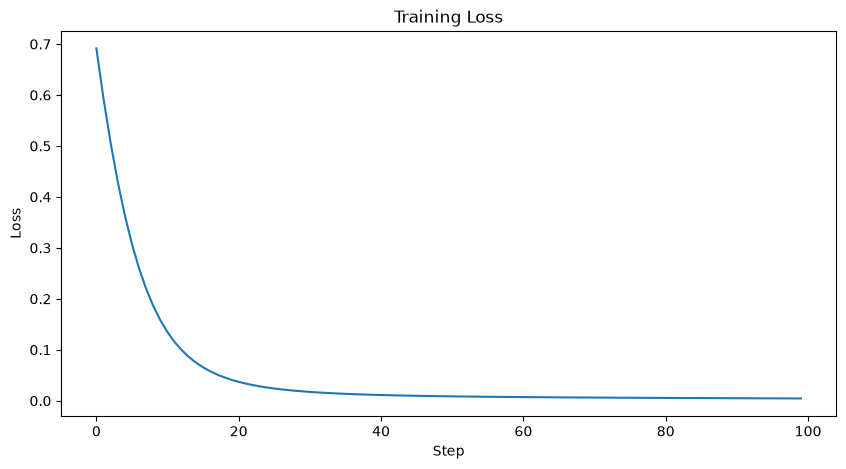

Text: 'The patient has a KRAS mutation.' => Prediction: Oncology related
Text: 'The weather in Seattle is rainy.' => Prediction: Not oncology related


In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

## Create a tiny dataset.
training_texts = [
    "The patient has an EGFR T790M mutation.",
    "KRAS G12D was detected in the tumor.",
    "The biopsy showed metastatic lung cancer.",
    "Seattle receives significant rainfall.",
    "The train arrives at the station at noon.",
    "The restaurant serves Italian food."
]

# 1 = oncology related
# 0 = not oncology related
labels = [1, 1, 1, 0, 0, 0]

# Generate embeddings once using a pretrained model. The embedding
# model is not finetuned. Only the linear classification head will be
# trained.
X = embedding_model.encode(training_texts, convert_to_tensor=True).clone().float()
print("Embedding shape: ", X.shape)

Y = torch.tensor(labels, dtype=torch.long)
print("Labels shape: ", Y.shape)

# Train the classifier
device = X.device ## making the device placement consistent with the embeddings.
classifier = nn.Linear(in_features=X.shape[1], out_features=2).to(device)
optimizer = torch.optim.Adam(classifier.parameters(), lr=0.01)
loss_fn = nn.CrossEntropyLoss()

losses = [] # for printing
for step in range(100):
    optimizer.zero_grad()

    logits = classifier(X)
    loss = loss_fn(logits, Y)
    
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    if step % 10 == 0:
        print(f"Step {step}, Loss: {loss.item()}")

print("Final loss:", loss.item())

## Plot the training losses.
plt.figure(figsize=(10, 5))
plt.plot(losses)
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

## Test the classifier on new sentences.
test_texts = [
    "The patient has a KRAS mutation.",
    "The weather in Seattle is rainy."
]

test_embeddings = embedding_model.encode(test_texts, convert_to_tensor=True).float().to(device)

with torch.no_grad():
    test_logits = classifier(test_embeddings)
    test_predictions = torch.argmax(test_logits, dim=1)

for text, prediction in zip(test_texts, test_predictions):
    label = "Oncology related" if prediction.item() == 1 else "Not oncology related"
    print(f"Text: '{text}' => Prediction: {label}")